<a href="https://colab.research.google.com/github/2303a510b9/Quantum-Computing-Hackathon/blob/main/prblm_57.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Quantum One-Class SVM for Novelty Detection Using Quantum Fidelity Kernels
This notebook walks through the end-to-end implementation of a Quantum One-Class SVM using PennyLane and Scikit-Learn for novelty detection on the Breast Cancer Wisconsin and Wine datasets.

In [1]:
!pip install -q pennylane scikit-learn numpy pandas matplotlib seaborn

In [2]:
import pennylane as qml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    recall_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)

In [3]:
# Load Datasets
# Breast Cancer Dataset (Inliers: Benign [original label 1], Outliers: Malignant [original label 0])
breast = load_breast_cancer()
X_bc = breast.data
y_bc = (breast.target == 0).astype(int)  # 1 = Malignant (Outlier), 0 = Benign (Inlier)

# Wine Dataset (Inliers: Class 0 [original label 0], Outliers: Classes 1 & 2 [original labels 1, 2])
wine = load_wine()
X_wine = wine.data
y_wine = (wine.target != 0).astype(int)  # 1 = Outlier, 0 = Inlier

print("BREAST CANCER DATASET")
print("Features:", X_bc.shape)
print("Inliers:", np.sum(y_bc == 0))
print("Outliers:", np.sum(y_bc == 1))

print("\nWINE DATASET")
print("Features:", X_wine.shape)
print("Inliers:", np.sum(y_wine == 0))
print("Outliers:", np.sum(y_wine == 1))

BREAST CANCER DATASET
Features: (569, 30)
Inliers: 357
Outliers: 212

WINE DATASET
Features: (178, 13)
Inliers: 59
Outliers: 119


In [4]:
def split_dataset(X, y):
    # Split 60% pool (for training) and 40% temp (validation + testing)
    X_pool, X_temp, y_pool, y_temp = train_test_split(
        X, y, test_size=0.40, random_state=42, stratify=y
    )
    # Split temp into 50% validation (20% total) and 50% testing (20% total)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
    )

    # Only inliers (normal class) are used for One-Class SVM training
    X_train = X_pool[y_pool == 0]

    print(f"Training inliers: {len(X_train)} | Validation samples: {len(X_val)} | Testing samples: {len(X_test)}")
    return X_train, X_val, X_test, y_val, y_test

bc_data = split_dataset(X_bc, y_bc)
wine_data = split_dataset(X_wine, y_wine)

Training inliers: 214 | Validation samples: 114 | Testing samples: 114
Training inliers: 35 | Validation samples: 36 | Testing samples: 36


In [5]:
def preprocess_data(X_train, X_val, X_test):
    # 1. Scale to feature range (-pi, pi) before PCA
    scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    # 2. PCA reduction to 4 components (for 4 qubits)
    pca = PCA(n_components=4, random_state=42)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_val_pca = pca.transform(X_val_scaled)
    X_test_pca = pca.transform(X_test_scaled)

    # 3. Scale PCA outputs back to range (-pi, pi) for quantum phase encoding
    final_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
    X_train_final = final_scaler.fit_transform(X_train_pca)
    X_val_final = final_scaler.transform(X_val_pca)
    X_test_final = final_scaler.transform(X_test_pca)

    return X_train_final, X_val_final, X_test_final

# Unpack bc_data: (X_train, X_val, X_test, y_val, y_test)
bc_processed = preprocess_data(bc_data[0], bc_data[1], bc_data[2])
wine_processed = preprocess_data(wine_data[0], wine_data[1], wine_data[2])

print("Preprocessed BC Training size:", bc_processed[0].shape)
print("Preprocessed Wine Training size:", wine_processed[0].shape)

Preprocessed BC Training size: (214, 4)
Preprocessed Wine Training size: (35, 4)


In [6]:
N_QUBITS = 4
dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev)
def quantum_feature_map(x):
    # Quantum data encoding using H, RY, and RZ gates
    for i in range(N_QUBITS):
        qml.Hadamard(wires=i)
        qml.RY(x[i], wires=i)
        qml.RZ(x[i], wires=i)

    # Circular entanglement between qubits
    for i in range(N_QUBITS - 1):
        qml.CNOT(wires=[i, i + 1])
    qml.CNOT(wires=[N_QUBITS - 1, 0])

    return qml.state()

# Verify circuit execution
test_state = quantum_feature_map(bc_processed[0][0])
print("Quantum State Dimension:", test_state.shape)

Quantum State Dimension: (16,)


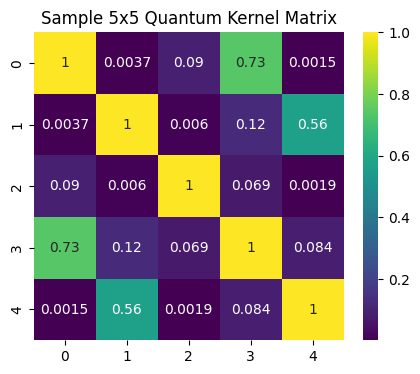

In [7]:
def generate_quantum_states(X):
    states = []
    for x in X:
        state = quantum_feature_map(x)
        states.append(state)
    return np.asarray(states)

def calculate_kernel(states_A, states_B):
    overlap = states_A.conj() @ states_B.T
    kernel = np.abs(overlap) ** 2
    return kernel.real

# Test kernel computation with a subset
sample_states = generate_quantum_states(bc_processed[0][:5])
sample_kernel = calculate_kernel(sample_states, sample_states)

plt.figure(figsize=(5, 4))
sns.heatmap(sample_kernel, annot=True, cmap="viridis")
plt.title("Sample 5x5 Quantum Kernel Matrix")
plt.show()

In [8]:
def train_quantum_ocsvm(X_train, nu=0.05):
    start = time.perf_counter()
    train_states = generate_quantum_states(X_train)
    K_train = calculate_kernel(train_states, train_states)

    model = OneClassSVM(kernel="precomputed", nu=nu)
    model.fit(K_train)
    training_time = time.perf_counter() - start
    return model, train_states, training_time

bc_model, bc_states, bc_train_time = train_quantum_ocsvm(bc_processed[0])
wine_model, wine_states, wine_train_time = train_quantum_ocsvm(wine_processed[0])

print(f"BC Training Time: {bc_train_time:.2f}s")
print(f"Wine Training Time: {wine_train_time:.2f}s")

BC Training Time: 1.72s
Wine Training Time: 0.26s


In [9]:
def get_anomaly_scores(model, train_states, X):
    start = time.perf_counter()
    test_states = generate_quantum_states(X)
    K_test = calculate_kernel(test_states, train_states)
    # Reverse scores so higher values indicate greater anomaly likelihood
    scores = -model.decision_function(K_test)
    inference_time = time.perf_counter() - start
    return scores, inference_time

bc_val_scores, bc_val_time = get_anomaly_scores(bc_model, bc_states, bc_processed[1])
bc_test_scores, bc_test_time = get_anomaly_scores(bc_model, bc_states, bc_processed[2])

wine_val_scores, wine_val_time = get_anomaly_scores(wine_model, wine_states, wine_processed[1])
wine_test_scores, wine_test_time = get_anomaly_scores(wine_model, wine_states, wine_processed[2])

In [10]:
def find_best_threshold(y_val, scores):
    precision, recall, thresholds = precision_recall_curve(y_val, scores)
    f1 = (2 * precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-10)
    best_index = np.argmax(f1)
    threshold = thresholds[best_index]
    print(f"Best Validation F1: {f1[best_index]:.4f} | Selected Threshold: {threshold:.4f}")
    return threshold

print("--- Tuning Breast Cancer Threshold ---")
bc_threshold = find_best_threshold(bc_data[3], bc_val_scores)

print("\n--- Tuning Wine Threshold ---")
wine_threshold = find_best_threshold(wine_data[3], wine_val_scores)

--- Tuning Breast Cancer Threshold ---
Best Validation F1: 0.7179 | Selected Threshold: 0.0193

--- Tuning Wine Threshold ---
Best Validation F1: 0.8000 | Selected Threshold: -0.0961


In [11]:
def evaluate_model(y_test, scores, threshold, name):
    predictions = (scores >= threshold).astype(int)
    auroc = roc_auc_score(y_test, scores)
    auprc = average_precision_score(y_test, scores)
    recall = recall_score(y_test, predictions, zero_division=0)

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn) if (fp + tn) else 0

    print(f"\n{'='*20} {name} Evaluation {'='*20}")
    print(f"AUROC:  {auroc:.4f}")
    print(f"AUPRC:  {auprc:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"FPR:    {fpr:.4f}")
    print("\nConfusion Matrix:")
    print(cm)
    print(f"{'='*50}")

    return {
        "Dataset": name,
        "AUROC": auroc,
        "AUPRC": auprc,
        "Recall": recall,
        "FPR": fpr
    }

bc_results = evaluate_model(bc_data[4], bc_test_scores, bc_threshold, "Breast Cancer")
wine_results = evaluate_model(wine_data[4], wine_test_scores, wine_threshold, "Wine")


==================== Breast Cancer Evaluation ====================
AUROC:  0.7533
AUPRC:  0.7899
Recall: 0.6190
FPR:    0.0694

Confusion Matrix:
[[67  5]
 [16 26]]

==================== Wine Evaluation ====================
AUROC:  0.4514
AUPRC:  0.6348
Recall: 1.0000
FPR:    1.0000

Confusion Matrix:
[[ 0 12]
 [ 0 24]]


In [12]:
def resource_report(name, X_train, X_test, train_time, inference_time):
    sample = X_train[0]
    specs = qml.specs(quantum_feature_map)(sample)
    depth = specs["resources"].depth

    print(f"\n{'='*20} {name} Quantum Cost Report {'='*20}")
    print("Qubits:", N_QUBITS)
    print("Circuit depth:", depth)
    print("Shots: 0 (analytic simulation)")
    print("Training quantum state preparations:", len(X_train))
    print("Inference quantum state preparations:", len(X_test))
    print("Training kernel entries calculated:", len(X_train) ** 2)
    print(f"Training Execution Time: {train_time:.4f}s")
    print(f"Inference Execution Time: {inference_time:.4f}s")
    print(f"{'='*55}")

resource_report("Breast Cancer", bc_processed[0], bc_processed[2], bc_train_time, bc_test_time)
resource_report("Wine", wine_processed[0], wine_processed[2], wine_train_time, wine_test_time)


==================== Breast Cancer Quantum Cost Report ====================
Qubits: 4
Circuit depth: 7
Shots: 0 (analytic simulation)
Training quantum state preparations: 214
Inference quantum state preparations: 114
Training kernel entries calculated: 45796
Training Execution Time: 1.7193s
Inference Execution Time: 0.7237s

==================== Wine Quantum Cost Report ====================
Qubits: 4
Circuit depth: 7
Shots: 0 (analytic simulation)
Training quantum state preparations: 35
Inference quantum state preparations: 36
Training kernel entries calculated: 1225
Training Execution Time: 0.2588s
Inference Execution Time: 0.1964s



FINAL RESULTS SUMMARY:


,Dataset,AUROC,AUPRC,Recall,FPR
0,Breast Cancer,0.753307,0.789868,0.619048,0.069444
1,Wine,0.451389,0.634846,1.000000,1.000000


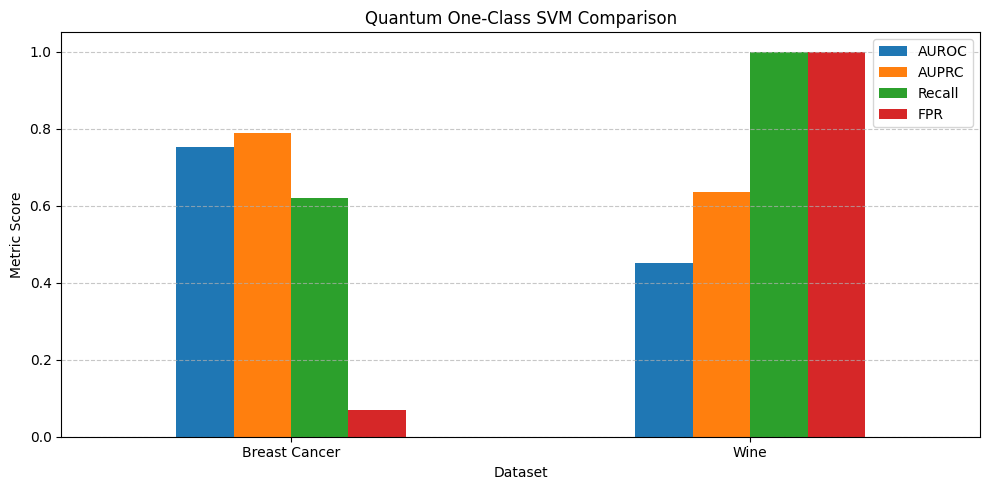

Results saved to 'quantum_one_class_svm_results.csv'.


In [13]:
results_df = pd.DataFrame([bc_results, wine_results])
print("\nFINAL RESULTS SUMMARY:")
display(results_df)

# Visualize Metrics
results_df.set_index("Dataset")[["AUROC", "AUPRC", "Recall", "FPR"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Quantum One-Class SVM Comparison")
plt.ylabel("Metric Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Export Results to CSV
results_df.to_csv("quantum_one_class_svm_results.csv", index=False)
print("Results saved to 'quantum_one_class_svm_results.csv'.")